# Lab 5: CNNs and ViTs vs. the Curse of Dimensionality
**CS6524 Computer Vision**, Immersive Software Engineering, University of Limerick
**Dara Heaphy** (23369914)

In this lab I trained a CNN family (**ConvNeXt**) and a Vision Transformer family (**Swin Transformer**) from scratch to predict depth from a single image (NYU Depth v2). I trained each model on the full training set and on a training set 6× smaller, to see which kind of architecture copes better when there is very little data for the size of the model.

All the reusable code (data loading, the model, the training loop, plots) is in the `mypylibs/` package in this repository, so this notebook only shows the experiment itself.

**Short version:** no model learned depth well. The best test MARE is 0.307, and a "model" that ignores the image and always outputs the average training depth map gets 0.372. ConvNeXt beats Swin at the tiny size, the base models are no better than the tiny ones, and on the reduced set every model ends up close to that no-image baseline.

## 0. Environment
The notebook runs on a Colab GPU runtime or on a local CUDA GPU. On Colab the data and outputs live on Google Drive. Locally they live in `data/` and `runs/` next to this notebook.

I ran all 16 training runs locally on an RTX 4080 Laptop GPU, using `train_all.py`, which uses exactly the same config as this notebook. The notebook then just loads the finished runs. Checkpoints, loss histories and test scores are saved every epoch, so an interrupted run carries on from its last epoch instead of starting again.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_URL = 'https://github.com/DaraHeaphy/lab5.git'
    DATA_DIR = '/content/drive/MyDrive/NYU_Depth'            # shortcut to the shared NYU Drive folder
    OUT_DIR  = '/content/drive/MyDrive/cs6524_lab5'
    if not os.path.exists('/content/lab5'):
        !git clone -q {REPO_URL} /content/lab5
    %cd /content/lab5
else:
    DATA_DIR = 'data'                                        # holds nyu_depth_v2_labeled.mat
    OUT_DIR  = 'runs'

!nvidia-smi -L

GPU 0: NVIDIA GeForce RTX 4080 Laptop GPU (UUID: GPU-59753f02-198b-da68-6e27-2ba5ea8eef53)


In [2]:
import torch, pandas as pd
from mypylibs.data import load_nyu, make_splits, NYUDepth, IMG_SIZE
from mypylibs.models import DepthNet, count_params, BACKBONES, FAMILY
from mypylibs.train import TrainConfig, run_experiment, load_model, run_name, baseline_mare
from mypylibs import plots

device = 'cuda'
torch.backends.cudnn.benchmark = True

## 1. Experimental setup

### Task
Monocular depth estimation: from one RGB image, predict the depth of every pixel in metres.

### Data
- **NYU Depth v2**, the labelled set: 1449 indoor scenes filmed with a Kinect. I load it from the official `nyu_depth_v2_labeled.mat` (on Colab, from the shared Drive folder).
- **Preprocessing.** I resize every image to **192 × 256** (H × W). This keeps NYU's 3:4 shape, and it divides by 32, which is the biggest stride in both backbones. The RGB image is resized bilinearly with anti-aliasing and normalised with the ImageNet mean and std. The depth map is resized with **nearest neighbour**, so I never make up a depth by blending a near and a far pixel, and it stays in metres. Pixels with depth 0 (missing, or padding from augmentation) are left out of both the loss and the metric. The resized set is cached to disk, so later runs load it in seconds.
- **Splits.** A fixed random 60% train / 20% validation / 20% test split (869 / 289 / 291 images), saved to `splits.json` so every model uses exactly the same images.
- **Reduced training set.** 10% of the whole dataset (145 images), sampled once from the training split. Every model uses these same 145 images. It is 6× smaller than the full training set, and the validation and test sets stay the same.

### Models: 4 backbones × 2 training sets = 8 runs
Every backbone is the torchvision version with `weights=None`, so it starts from random weights. I replace its classification head with the **same small FPN decoder** for every model:
1. Take the outputs of the 4 stages (strides 4, 8, 16, 32).
2. Bring each one to 128 channels with a 1×1 conv.
3. Merge them from coarse to fine, with upsampling and 3×3 conv, GroupNorm and GELU blocks.
4. Predict 1 channel at 1/4 resolution, upsample it bilinearly to full size, and apply a softplus so the depth is always positive.

Only the encoder changes between runs, so any difference comes from the architecture.

| Backbone | Family | Built-in assumptions |
|---|---|---|
| ConvNeXt-T / ConvNeXt-B | CNN | locality and weight sharing are built in, so a filter that works in one place works everywhere |
| Swin-T / Swin-B | ViT | self-attention inside shifted local windows; most of the spatial structure has to be *learned* |

The tiny and base versions of the two families are almost the same size (about 28M and 88M parameters, see the table below), so comparing CNN against ViT at each size is fair.

### Training (the same for every run)
- **Loss:** Huber loss (δ = 1 m) on valid pixels.
- **Optimiser:** AdamW (lr 3e-4, weight decay 0.05), 3 epochs of linear warm-up, then cosine decay.
- **Batch size and epochs:** batch size 16, 50 epochs. On my GPU a full-set run takes 4–8 minutes, so the whole grid fits easily before the deadline.
- **Numerics:** mixed precision (fp16), gradient clipping at 1.0, seed 0.
- **Model selection:** I keep the weights from the epoch with the **lowest validation loss**.
- **Evaluation:** **Mean Absolute Relative Error**, MARE = mean(|d̂ − d| / d) over valid pixels. I average it per image, then over the 291 test images.

The brief asks for the same number of *epochs* on both training sets, so the reduced runs also get 6× fewer training steps (450 instead of 2700). I come back to this in the discussion.

In [3]:
BACKBONES_ = list(BACKBONES)            # ['convnext_tiny', 'convnext_base', 'swin_t', 'swin_b']
SUBSETS = ['full', 'reduced']
cfg = TrainConfig(epochs=50, batch_size=16, lr=3e-4, weight_decay=0.05, warmup_epochs=3, huber_delta=1.0,
                  num_workers=2 if IN_COLAB else 0)   # data is already in RAM; Windows workers only add overhead

pd.DataFrame([{'model': b, 'family': FAMILY[b], 'params (M)': round(count_params(DepthNet(b)), 1)}
              for b in BACKBONES_]).set_index('model')

,family,params (M)
model,,
convnext_tiny,CNN,28.7
convnext_base,CNN,88.5
swin_t,ViT,28.4
swin_b,ViT,87.7


## 2. Data preparation
A few training images with their depth maps. Close objects are light and far ones are dark.

In [4]:
rgb, depth = load_nyu(DATA_DIR, cache_path=f'{OUT_DIR}/nyu_{IMG_SIZE[0]}x{IMG_SIZE[1]}.pt')
splits = make_splits(len(rgb), seed=42, path=f'{OUT_DIR}/splits.json')

print(f'{len(rgb)} images, RGB {tuple(rgb.shape[1:])}, depth range {depth[depth > 0].min():.2f}-{depth.max():.2f} m')
pd.Series({k: len(v) for k, v in splits.items()}, name='images').to_frame().T

C:\Users\darah\MastersBlock2\CV\labs\lab5\mypylibs\data.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  d = torch.load(cache_path)


1449 images, RGB (3, 192, 256), depth range 0.71-9.99 m


,train,val,test,reduced
images,869,289,291,145


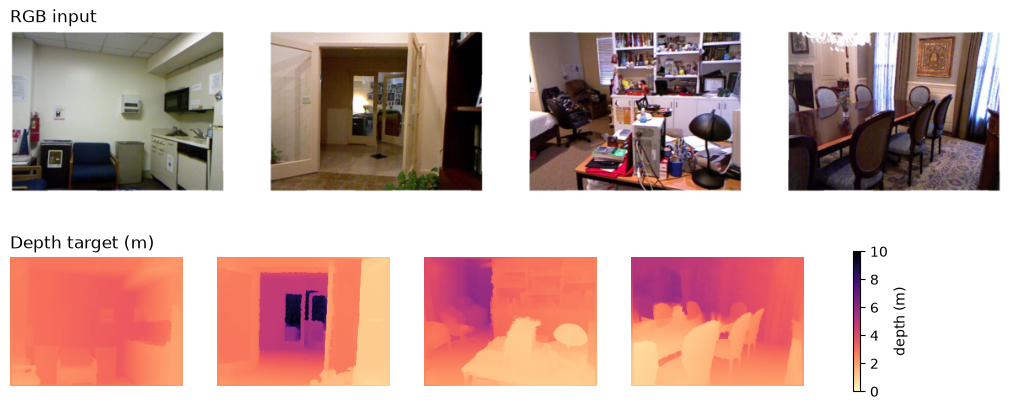

In [5]:
def datasets(subset, augment=False):
    train_idx = splits['train'] if subset == 'full' else splits['reduced']
    return (NYUDepth(rgb, depth, train_idx, augment=augment),
            NYUDepth(rgb, depth, splits['val']),
            NYUDepth(rgb, depth, splits['test']))

plots.show_samples(datasets('full')[0])

## 3. Training
The eight runs. A run that has already finished is skipped, and a half-finished one carries on from its last checkpoint, so it is safe to run this cell again. The test MARE is computed once, using the weights from the best validation epoch.

In [6]:
histories, results = {}, {}
for subset in SUBSETS:
    for b in BACKBONES_:
        name = run_name(b, subset, augment=False)
        histories[name], results[name] = run_experiment(b, subset, False, datasets, cfg, OUT_DIR, device)

## 4. Training and validation loss curves
Rows are the training set, columns the backbone. The dotted line marks the epoch with the lowest validation loss, which gives the weights I test.

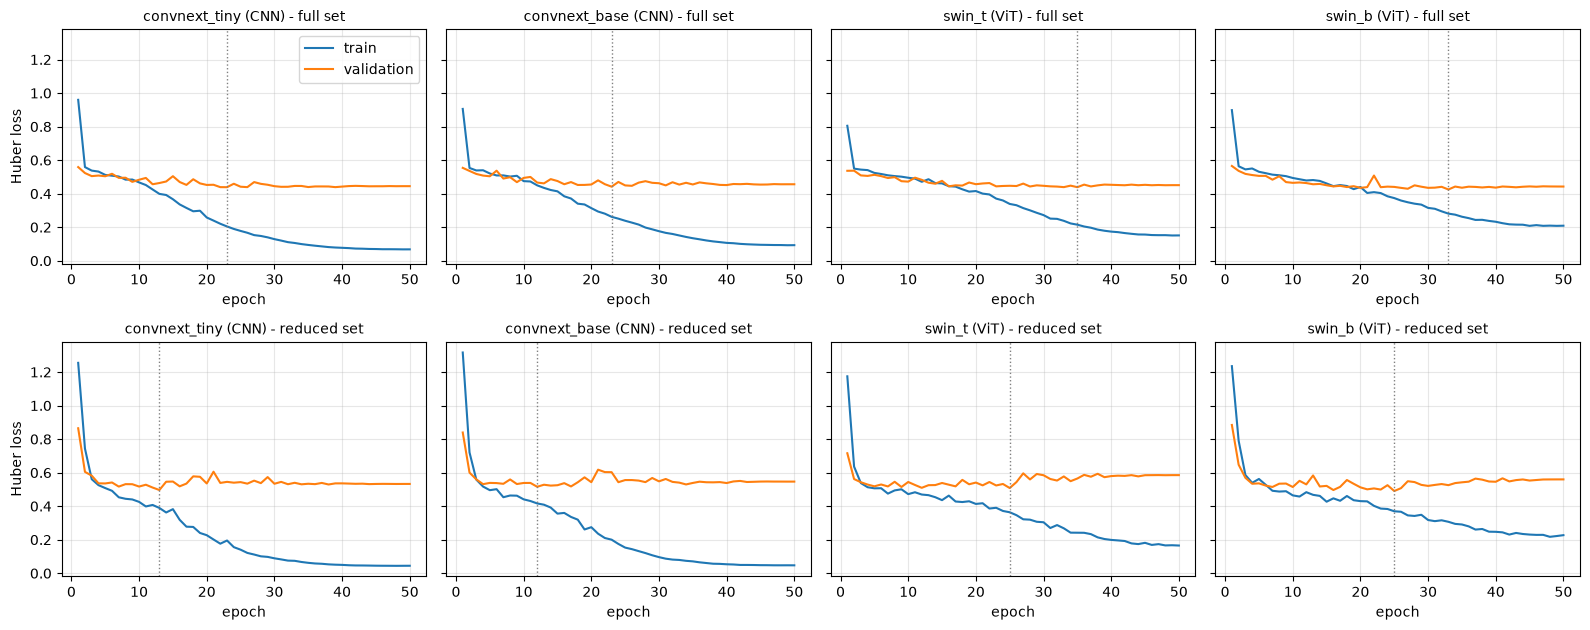

In [7]:
plots.plot_loss_curves(histories, BACKBONES_, SUBSETS)

In every run the training loss keeps falling while the validation loss flattens out at about 0.44 (full set) or 0.50–0.55 (reduced set) within the first 10–20 epochs, and then creeps back up. All four models end up with almost the same best validation loss (0.425–0.442 on the full set), so the architectures differ much more in how fast they memorise the training set than in how well they generalise. ConvNeXt drives its training loss to almost zero (0.05–0.09), and Swin stays higher (0.15–0.23).

## 5. Test-set performance (MARE)
*Degradation* is how much the test MARE goes up when a model is trained on the reduced set instead of the full set. I use it as the measure of robustness to having less data.

To know what a good MARE is, I also score two predictors that never look at the image: the median training depth everywhere, and the per-pixel average of all the training depth maps (an "average room"). A model only learned something from the images if it beats these.

In [8]:
table = plots.results_table(results, BACKBONES_, SUBSETS)
table.style.format(precision=3)

,family,MARE full,MARE reduced,degradation (%)
model,,,,
convnext_tiny,CNN,0.318,0.348,9.440
convnext_base,CNN,0.320,0.369,15.255
swin_t,ViT,0.352,0.361,2.549
swin_b,ViT,0.325,0.357,10.145


In [9]:
baselines = baseline_mare(depth, splits)
pd.Series(baselines, name='test MARE').to_frame().style.format(precision=3)

,test MARE
median depth everywhere,0.392
mean training depth map,0.372


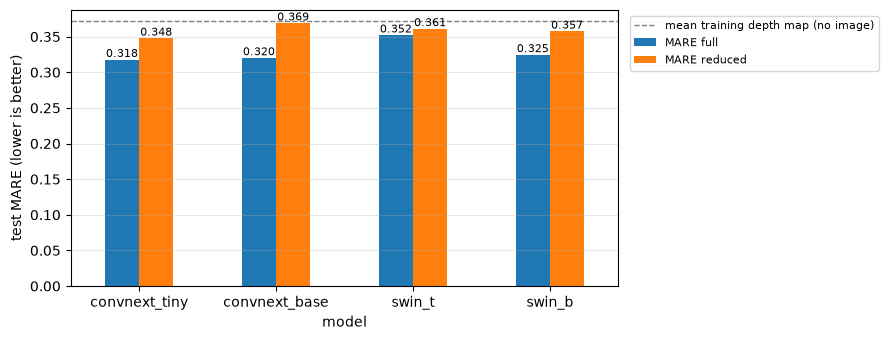

In [10]:
plots.plot_mare_bars(table, baseline=baselines['mean training depth map'])

The 291 test images have a per-image MARE standard deviation of about 0.2, so each test MARE is only accurate to roughly ±0.01. Every run also uses a single seed. So I treat differences below about 0.02 as ties.

### Overfitting
The *gap* is the validation loss minus the training loss. "At best" is the gap at the epoch I keep, and "at end" is the gap after all 50 epochs.

In [11]:
plots.gap_table(histories, BACKBONES_, SUBSETS).style.format(precision=3)

,family,best epoch (full),gap at best (full),gap at end (full),best epoch (reduced),gap at best (reduced),gap at end (reduced)
model,,,,,,,
convnext_tiny,CNN,23,0.234,0.377,13,0.107,0.488
convnext_base,CNN,23,0.180,0.363,12,0.099,0.499
swin_t,ViT,35,0.224,0.300,25,0.145,0.420
swin_b,ViT,33,0.144,0.234,25,0.121,0.333


### Example predictions
Four test images, with the tiny model of each family trained on each training set. The colour scale is the same as in the data section (0–10 m).

C:\Users\darah\MastersBlock2\CV\labs\lab5\mypylibs\train.py:179: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(os.path.join(run_dir, 'best.p

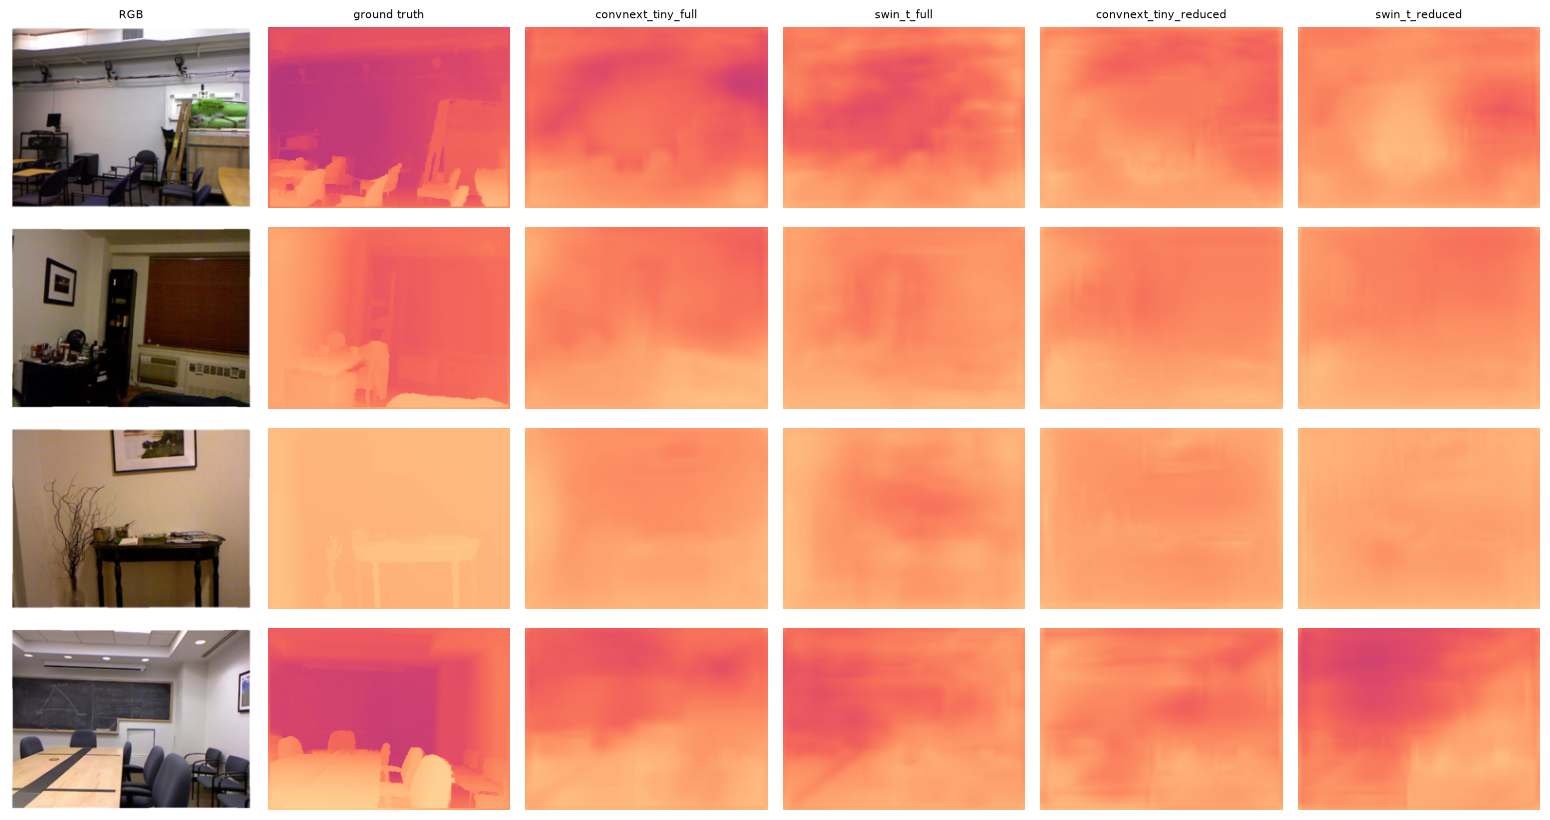

In [12]:
test_ds = datasets('full')[2]
models = {run_name(b, s, False): load_model(b, f'{OUT_DIR}/{run_name(b, s, False)}', device)
          for s in SUBSETS for b in ('convnext_tiny', 'swin_t')}
plots.show_predictions(models, test_ds, indices=[0, 15, 30, 45], device=device)

## 6. Discussion

### Accuracy
- **ConvNeXt-T is the best model without augmentation, at 0.318.** At the tiny size the CNN clearly beats the ViT (0.318 vs 0.352, about three times the noise level). At the base size they tie (0.320 vs 0.325).
- **The bigger models don't help.** ConvNeXt-B is no better than ConvNeXt-T on the full set (0.320 vs 0.318) and worse on the reduced set (0.369 vs 0.348). Swin-B beats Swin-T on the full set (0.325 vs 0.352), but Swin-T looks like the weak run here rather than Swin-B being a strong one. Three times the parameters on 869 images just gives the model more room to memorise.
- **None of these MAREs is good.** The best model is only about 15% better than outputting the average training depth map (0.318 vs 0.372). The predictions above show why: they are blurry, and they mostly learned "the top of the image is far and the bottom is near", plus a rough idea of where the back wall is. Chairs, tables and object edges don't show up at all.

### Robustness (full → reduced)
- Going to the reduced set makes every model worse: +9% (ConvNeXt-T), +15% (ConvNeXt-B), +3% (Swin-T) and +10% (Swin-B).
- **This is the opposite of what I expected.** I expected Swin to drop more, because a CNN has locality built in and a transformer has to learn it from data. In my runs ConvNeXt-B drops the most and Swin-T the least.
- I don't think this means Swin is more robust. On the reduced set all four models land between 0.348 and 0.369, which is within 0.025 of the no-image baseline (0.372). With 145 images none of them learns much more than the average room, so the degradation mostly measures how good the model was on the full set. Swin-T had the least to lose. Even on the reduced set the CNN (ConvNeXt-T, 0.348) is still the best model.

### Generalisation
- **Every run overfits badly.** The loss curves show it clearly. On the full set the training loss ends at 0.07–0.21 while the validation loss stays at 0.44–0.46. On the reduced set the gap at the end is even bigger, 0.33–0.50, because ConvNeXt pushes its training loss to 0.05 while the validation loss rises to 0.53–0.55.
- **ConvNeXt overfits earliest.** Its best epoch is 23 on the full set and 12–13 on the reduced set. Swin's is 33–35 and 25. ConvNeXt fits the training images faster, which also means it starts memorising them sooner.
- **The validation loss barely moves.** Every model reaches roughly its final validation loss within the first 10–20 epochs, and the epochs after that only make the training loss smaller. All the extra training is spent memorising the training images.

### The curse of dimensionality
**How is it evident in my experiments?**
Each input is 192×256×3 ≈ 147k numbers, each output is 49k depth values, and the models have 28–88M parameters. To cover that space I only have 869 training images (or 145 on the reduced set). With so few samples in such a big space, the models can memorise every training image instead of learning how depth actually works in a room. My results show this in four ways:
- The training loss goes to almost zero while the validation loss stays flat at about 0.44, so the models memorise rather than generalise (the gap table above).
- The bigger (base) models are no better, and on the reduced set ConvNeXt-B is worse than ConvNeXt-T. More parameters only add more ways to fit the same few images.
- On the reduced set every model is almost as bad as the no-image baseline (0.348–0.369 vs 0.372). There isn't enough data to learn anything beyond the average room.
- The predictions are blurry average rooms rather than real depth maps.

I expected the curse to hit the ViTs harder, because they have fewer built-in assumptions and so a bigger space of functions to search. My results only partly show this. Swin-T is clearly worse than ConvNeXt-T on the full set, but on the reduced set the data is so scarce that every model collapses to roughly the same baseline, so there is no real difference left to see.

**Was it solved?**
No. Trained from scratch, no model gets anywhere near a usable depth map. The best MARE (0.307, with augmentation) means the depth is off by about 30% on average, and the best model is only about 17% better than ignoring the image. Every model also gets worse when there is less data.

**What would I do next?** Anything that either adds data or shrinks the space the model has to search:
1. **Transfer learning:** start from ImageNet-pretrained weights. This is the biggest single fix, especially for the ViTs, which need a lot of data to learn spatial structure from scratch.
2. **More data:** the raw NYU set has about 400k video frames instead of 1449 labelled ones, and other indoor depth datasets could be added.
3. **Self-supervised pre-training:** for example MAE or DINO on unlabelled indoor images, so the encoder learns about rooms before it ever sees a depth label.
4. **Stronger priors and regularisation:** smaller models, stochastic depth, early stopping, or a hybrid with a convolutional stem in front of the transformer.
5. **Data augmentation:** tested in the bonus below. It helps, but nowhere near enough on its own.

## 7. Bonus: data augmentation
I ran the same 8 runs again, with these augmentations applied to the RGB image and its depth map **together**, so they always stay aligned:
- horizontal flip (p = 0.5)
- random crop (75–100% of each side), resized back to 192 × 256
- rotation (±5°); the corners that get padded get depth 0, so they are left out of the loss
- colour jitter (brightness, contrast, saturation, hue), on the RGB image only

The validation and test sets are never augmented. Augmented images are generated in the main process, so these runs took 2–3× longer (10–14 minutes per full-set run).

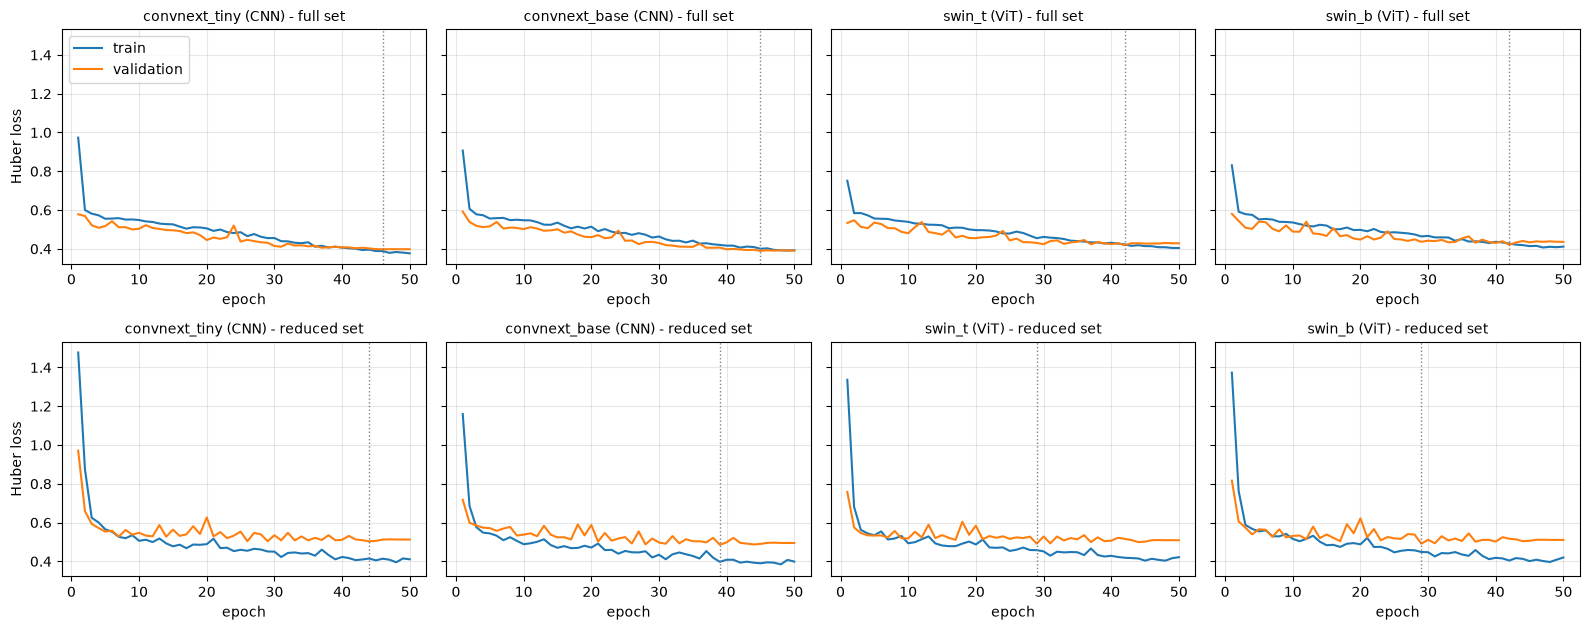

,family,MARE full,MARE reduced,degradation (%),MARE full (aug),MARE reduced (aug),degradation (%) (aug)
model,,,,,,,
convnext_tiny,CNN,0.318,0.348,9.440,0.311,0.381,22.410
convnext_base,CNN,0.320,0.369,15.255,0.307,0.366,19.135
swin_t,ViT,0.352,0.361,2.549,0.333,0.364,9.147
swin_b,ViT,0.325,0.357,10.145,0.342,0.369,7.963


,family,best epoch (full),gap at best (full),gap at end (full),best epoch (reduced),gap at best (reduced),gap at end (reduced)
model,,,,,,,
convnext_tiny,CNN,46,0.010,0.021,44,0.088,0.102
convnext_base,CNN,45,-0.011,-0.002,39,0.088,0.096
swin_t,ViT,42,-0.004,0.024,29,0.033,0.088
swin_b,ViT,42,-0.006,0.024,29,0.043,0.091


In [13]:
RUN_AUG = True
if RUN_AUG:
    for subset in SUBSETS:
        for b in BACKBONES_:
            name = run_name(b, subset, augment=True)
            histories[name], results[name] = run_experiment(b, subset, True, datasets, cfg, OUT_DIR, device)

    plots.plot_loss_curves(histories, BACKBONES_, SUBSETS, suffix='_aug')
    aug = plots.results_table(results, BACKBONES_, SUBSETS, suffix='_aug')
    comparison = table[['family', 'MARE full', 'MARE reduced', 'degradation (%)']].join(
        aug.drop(columns='family').add_suffix(' (aug)'))
    display(comparison.style.format(precision=3))
    display(plots.gap_table(histories, BACKBONES_, SUBSETS, suffix='_aug').style.format(precision=3))

### Discussion of the bonus
- **Augmentation stops the overfitting.** On the full set the training and validation curves now stay together (gap at the end ≤ 0.03, instead of 0.23–0.38 without it). The best epoch moves to 42–46, near the end of training, and the curves are still going down at epoch 50, so these models could have trained for longer.
- **On the full set it lowers the test MARE for three of the four models:** ConvNeXt-B 0.320 → **0.307** (the best result in the lab), ConvNeXt-T 0.318 → 0.311 and Swin-T 0.352 → 0.333. Swin-B gets worse (0.325 → 0.342). Most of these changes are within about twice the noise, so the clearest results are the best one (ConvNeXt-B) and Swin-T's improvement.
- **On the reduced set it doesn't help.** ConvNeXt-T gets worse (0.348 → 0.381), and the other three stay about the same (0.364–0.369). A big reason is the number of steps: the reduced runs get only 450 steps, and with augmentation every image looks different each time, so the model needs *more* steps to fit, not fewer. The reduced runs also still overfit (gap at the end of about 0.09–0.10).
- **Does it help Swin more than ConvNeXt?** I expected it to, because augmentation adds the kind of prior (flip and shift invariance) that a ViT lacks. Swin-T gained the most on the full set (−5%), but Swin-B got worse, so I can't say it helps ViTs more in general.
- **Overall**, augmentation fixes the *symptom* (the train–validation gap) but not the *cause*. Even the best augmented model is only about 17% better than the no-image baseline. Flips and crops are new views of the same 869 rooms, not new rooms, so the model still has very little to learn from. That's why transfer learning or more data are the real next steps.